Qiskit environment ready.

=== CORE CIRCUIT (1024 shots) ===
{'11': 537, '00': 487}

=== SHOT-COUNT COMPARISON ===
shots=  100: {'00': 54, '11': 46}
shots= 1000: {'11': 495, '00': 505}
shots=10000: {'11': 5015, '00': 4985}

=== FIVE INDEPENDENT 100-SHOT RUNS ===
run 1: {'11': 46, '00': 54}
run 2: {'11': 50, '00': 50}
run 3: {'11': 57, '00': 43}
run 4: {'11': 54, '00': 46}
run 5: {'00': 56, '11': 44}

=== REMOVED CNOT (1024 shots) ===
{'00': 526, '01': 498}

=== SWAPPED H TARGET (1024 shots) ===
{'11': 520, '00': 504}


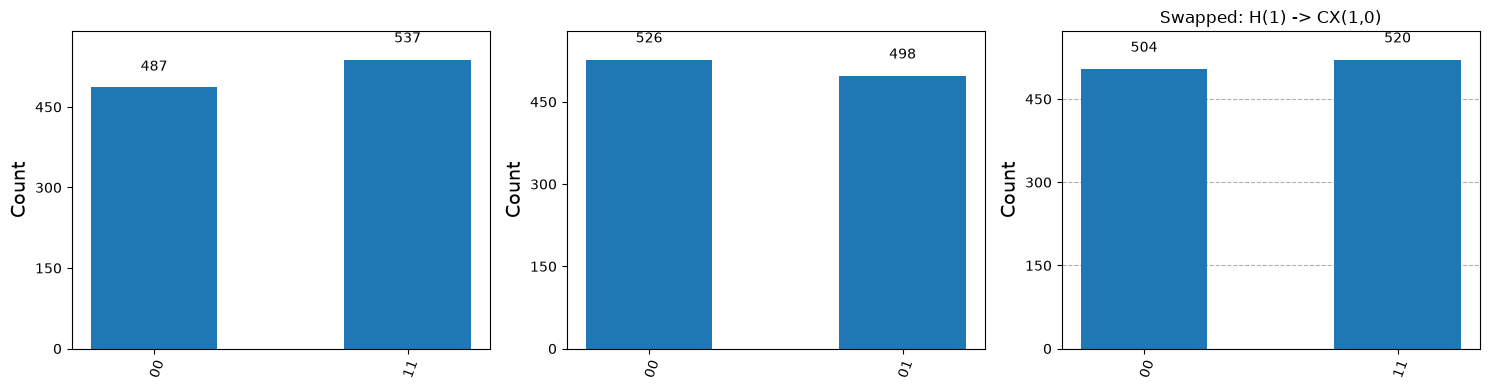


All experiments complete.


In [1]:
# ============================================================
# Quantum Safe — Bell State Solution
# Qiskit Fall Fest Nairobi 2026 — Challenge 03
# ============================================================

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

sim = AerSimulator()
print("Qiskit environment ready.")

# ------------------------------------------------------------
# 1. CORE CIRCUIT: H(0) -> CX(0,1)
# ------------------------------------------------------------
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

result = sim.run(transpile(qc, sim), shots=1024).result()
counts = result.get_counts()
print("\n=== CORE CIRCUIT (1024 shots) ===")
print(counts)

plot_histogram(counts, title="Core: H(0) -> CX(0,1) — 1024 shots", figsize=(7, 4))
plt.show()

# ------------------------------------------------------------
# 2. SHOT-COUNT COMPARISON: 100 / 1000 / 10000
# ------------------------------------------------------------
print("\n=== SHOT-COUNT COMPARISON ===")
for shots in [100, 1000, 10000]:
    r = sim.run(transpile(qc, sim), shots=shots).result()
    print(f"shots={shots:>5}: {r.get_counts()}")

# ------------------------------------------------------------
# 3. FIVE INDEPENDENT 100-SHOT RUNS
# ------------------------------------------------------------
print("\n=== FIVE INDEPENDENT 100-SHOT RUNS ===")
for i in range(5):
    r = sim.run(transpile(qc, sim), shots=100).result()
    print(f"run {i+1}: {r.get_counts()}")

# ------------------------------------------------------------
# 4. REMOVED CNOT: H(0) ONLY
# ------------------------------------------------------------
qc_no_cx = QuantumCircuit(2)
qc_no_cx.h(0)
qc_no_cx.measure_all()

r_nocx = sim.run(transpile(qc_no_cx, sim), shots=1024).result()
counts_nocx = r_nocx.get_counts()
print("\n=== REMOVED CNOT (1024 shots) ===")
print(counts_nocx)

# ------------------------------------------------------------
# 5. SWAPPED H TARGET: H(1) -> CX(1,0)
# ------------------------------------------------------------
qc_swap = QuantumCircuit(2)
qc_swap.h(1)
qc_swap.cx(1, 0)
qc_swap.measure_all()

r_swap = sim.run(transpile(qc_swap, sim), shots=1024).result()
counts_swap = r_swap.get_counts()
print("\n=== SWAPPED H TARGET (1024 shots) ===")
print(counts_swap)

# ------------------------------------------------------------
# 6. THREE-PANEL COMPARISON FIGURE
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_histogram(counts, title="Core: H(0) -> CX(0,1)", ax=axes[0])
plot_histogram(counts_nocx, title="No CNOT: H(0) only", ax=axes[1])
plot_histogram(counts_swap, title="Swapped: H(1) -> CX(1,0)", ax=axes[2])
plt.tight_layout()
plt.show()

print("\nAll experiments complete.")